# Performance Analysis of ResNet50 Transfer Learning for Indian Traffic Sign Recognition

## 1. Project Introduction

**Goal:** investigate whether transfer learning and fine-tuning improve Indian traffic-sign classification compared with training the same architecture from scratch.

**Only one architecture is used: ResNet50.** Three experimental conditions are compared on the *same* train / validation / test split:

| # | Condition | What is trained |
|---|-----------|-----------------|
| 1 | ResNet50 from scratch | All layers, random initialisation |
| 2 | ImageNet-pretrained + frozen backbone (feature extraction) | Only the new classification head |
| 3 | ImageNet-pretrained + fine-tuning | Head + selected deeper layers (`layer4` by default) |

**Rules followed in this notebook**
- The test set is used **only once**, for the final evaluation (never for training, tuning or model selection).
- Every number reported comes from actually running the code. Nothing is hard-coded.
- No other architectures, ensembles or limited-data experiments are included.

## 2. Environment Setup

In [ ]:
!pip install -q kaggle scikit-learn seaborn pandas matplotlib tqdm

In [ ]:
import os, sys, json, random, time, shutil, zipfile, copy, platform, subprocess, hashlib
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

# ---------- Reproducibility: fixed seeds for Python, NumPy and PyTorch ----------
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    # Deterministic cuDNN kernels (slightly slower, but repeatable where practical).
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print('Libraries imported. Seed =', SEED)

Libraries imported. Seed = 42


## 3. GPU Check
Training ResNet50 on a CPU is very slow. In Colab: **Runtime -> Change runtime type -> GPU**.

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'      # mixed precision: faster + less memory on GPU

print('CUDA available :', torch.cuda.is_available())
if device.type == 'cuda':
    print('GPU name       :', torch.cuda.get_device_name(0))
    print('GPU memory     : %.1f GB' % (torch.cuda.get_device_properties(0).total_memory / 1e9))
else:
    print('WARNING: no GPU found. Training will be extremely slow.')
print('Device used    :', device)
print('Mixed precision:', USE_AMP)

CUDA available : True
GPU name       : Tesla T4
GPU memory     : 15.6 GB
Device used    : cuda
Mixed precision: True


## 4. Google Drive Setup
Colab's runtime is temporary, so checkpoints, models, results and plots are all stored in Google Drive.

```
Google Drive/Traffic_Sign_ResNet50/
    dataset/      <- put the dataset .zip here (or kaggle.json)
    checkpoints/  <- resumable training checkpoints
    models/       <- final saved models
    results/      <- histories, metrics, reports (CSV / JSON / TXT)
    plots/        <- figures for the report
```

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# ---- Configurable paths ----
PROJECT_DIR = Path('/content/drive/MyDrive/Traffic_Sign_ResNet50')
DATASET_DIR = PROJECT_DIR / 'dataset'
CKPT_DIR    = PROJECT_DIR / 'checkpoints'
MODEL_DIR   = PROJECT_DIR / 'models'
RESULT_DIR  = PROJECT_DIR / 'results'
PLOT_DIR    = PROJECT_DIR / 'plots'

for d in [DATASET_DIR, CKPT_DIR, MODEL_DIR, RESULT_DIR, PLOT_DIR]:
    d.mkdir(parents=True, exist_ok=True)
    print('Ready:', d)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ready: /content/drive/MyDrive/Traffic_Sign_ResNet50/dataset
Ready: /content/drive/MyDrive/Traffic_Sign_ResNet50/checkpoints
Ready: /content/drive/MyDrive/Traffic_Sign_ResNet50/models
Ready: /content/drive/MyDrive/Traffic_Sign_ResNet50/results
Ready: /content/drive/MyDrive/Traffic_Sign_ResNet50/plots


### Project configuration
All hyper-parameters live in one place so they are easy to explain and change.

In [ ]:
CFG = {
    'seed'            : SEED,
    'img_size'        : 224,       # ResNet50 standard input resolution
    'batch_size'      : 64,        # reduce to 32 if you get an out-of-memory error
    'num_workers'     : 2,
    'val_ratio'       : 0.15,      # fraction of ALL data used for validation
    'test_ratio'      : 0.15,      # fraction of ALL data used for test (used only at the end)

    'epochs_scratch'  : 40,        # max epochs (early stopping may stop sooner)
    'epochs_frozen'   : 15,
    'epochs_finetune' : 20,

    'lr_scratch'      : 1e-3,      # random init -> can use a larger LR
    'lr_head'         : 1e-3,      # new head on frozen features
    'lr_finetune'     : 1e-4,      # SMALLER LR so pretrained weights are not destroyed
    'weight_decay'    : 1e-4,
    'patience'        : 7,         # early stopping patience (epochs)
    'dropout'         : 0.3,       # dropout before the new classification layer
    'imbalance_threshold': 3.0,    # max/min class ratio above which class weights are used

    'ft_unfreeze'     : ['layer4'],  # which ResNet stages to unfreeze in Stage 2
}
RESUME = False   # set True to resume an interrupted run from its last checkpoint in Drive
print(json.dumps(CFG, indent=2))

{
  "seed": 42,
  "img_size": 224,
  "batch_size": 64,
  "num_workers": 2,
  "val_ratio": 0.15,
  "test_ratio": 0.15,
  "epochs_scratch": 40,
  "epochs_frozen": 15,
  "epochs_finetune": 20,
  "lr_scratch": 0.001,
  "lr_head": 0.001,
  "lr_finetune": 0.0001,
  "weight_decay": 0.0001,
  "patience": 7,
  "dropout": 0.3,
  "imbalance_threshold": 3.0,
  "ft_unfreeze": [
    "layer4"
  ]
}


## 5. Dataset Acquisition

**Recommended dataset:** Kaggle - *Indian Traffic Sign Dataset* (`neelpratiksha/indian-traffic-sign-dataset`), described as images of 59 classes of Indian traffic signs plus a CSV file.

**Three ways to get it into Colab (the code tries them in this order):**
1. **Upload the zip manually (simplest).** Download the zip from the Kaggle page in your browser and put it in `Google Drive/Traffic_Sign_ResNet50/dataset/`.
2. **Kaggle API.** Create an API token on Kaggle (Settings -> API), upload `kaggle.json` to `Google Drive/Traffic_Sign_ResNet50/`, and the code will download the dataset for you.
3. **Already-extracted folders** placed inside `dataset/` are copied as-is.

The data is extracted to Colab's *local* disk (`/content/...`) because reading thousands of small images from Drive is very slow.

In [ ]:
DATASET_SLUG = 'neelpratiksha/indian-traffic-sign-dataset'
LOCAL_DATA = Path('/content/indian_traffic_signs')

def setup_kaggle_credentials():
    # Returns True if Kaggle API credentials are available.
    kaggle_json = PROJECT_DIR / 'kaggle.json'
    if kaggle_json.exists():
        dst = Path.home() / '.kaggle'
        dst.mkdir(exist_ok=True)
        shutil.copy(kaggle_json, dst / 'kaggle.json')
        os.chmod(dst / 'kaggle.json', 0o600)
        return True
    return (Path.home() / '.kaggle' / 'kaggle.json').exists() or 'KAGGLE_USERNAME' in os.environ

def prepare_dataset():
    if LOCAL_DATA.exists() and any(LOCAL_DATA.iterdir()):
        print('Dataset already on local disk:', LOCAL_DATA)
        return
    LOCAL_DATA.mkdir(parents=True, exist_ok=True)

    zips = sorted(DATASET_DIR.glob('*.zip'))
    if not zips and setup_kaggle_credentials():
        print('Downloading dataset from Kaggle ...')
        subprocess.run(['kaggle', 'datasets', 'download', '-d', DATASET_SLUG,
                        '-p', str(DATASET_DIR)], check=True)
        zips = sorted(DATASET_DIR.glob('*.zip'))

    if zips:
        for z in zips:
            print('Extracting', z.name, '...')
            with zipfile.ZipFile(z) as zf:
                zf.extractall(LOCAL_DATA)
    elif any(p.is_dir() for p in DATASET_DIR.iterdir()):
        print('Copying extracted folders from Drive to local disk ...')
        for p in DATASET_DIR.iterdir():
            if p.is_dir():
                shutil.copytree(p, LOCAL_DATA / p.name, dirs_exist_ok=True)
    else:
        shutil.rmtree(LOCAL_DATA)
        raise FileNotFoundError(
            'Dataset not found.\n'
            f'Option A: download the zip from https://www.kaggle.com/datasets/{DATASET_SLUG}\n'
            f'          and upload it to {DATASET_DIR}\n'
            f'Option B: upload kaggle.json to {PROJECT_DIR} and re-run this cell.')
    print('Dataset ready at', LOCAL_DATA)

prepare_dataset()

Dataset already on local disk: /content/indian_traffic_signs


## 6. Dataset Inspection
The code **automatically finds** the folder that contains one sub-folder per class (ImageFolder style), reads the class names from the folder names, removes unreadable images, and removes **exact duplicate files** (by MD5 hash) so identical images cannot end up in both the training and test sets.

In [ ]:
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.ppm', '.webp'}

def natural_key(s):
    return (0, int(s), s) if s.isdigit() else (1, 0, s)

def count_images(folder):
    return sum(1 for f in folder.iterdir() if f.is_file() and f.suffix.lower() in IMG_EXTS)

def find_class_roots(base):
    # Find folders whose sub-folders each contain images (= class folders).
    found = []
    dirs = [base] + [p for p in base.rglob('*') if p.is_dir()]
    for d in dirs:
        if '__MACOSX' in d.parts:
            continue
        subs = [s for s in d.iterdir() if s.is_dir()]
        good = [s for s in subs if count_images(s) > 0]
        if len(good) >= 5 and len(good) >= 0.9 * len(subs):
            found.append((d, len(good), sum(count_images(s) for s in good)))
    return sorted(found, key=lambda t: -t[2])

def show_tree(base, depth=2):
    print('Folder structure under', base)
    for p in sorted(base.rglob('*')):
        rel = p.relative_to(base)
        if len(rel.parts) <= depth:
            print('  ' * (len(rel.parts) - 1) + ('[dir] ' if p.is_dir() else '') + p.name)
    for csv in list(base.rglob('*.csv'))[:3]:
        print('\nFirst rows of', csv.name)
        print(pd.read_csv(csv).head())

candidates = find_class_roots(LOCAL_DATA)
if not candidates:
    show_tree(LOCAL_DATA)
    raise RuntimeError('No ImageFolder-style class folders found. Check the tree above and '
                       'set DATA_ROOT manually in the next cell.')

print('Candidate class roots (folder, #classes, #images):')
for c in candidates:
    print('  ', c)

# If the printout shows several candidates (e.g. separate train/ and test/ folders),
# set DATA_ROOT yourself and, if the dataset ships an official test folder, OFFICIAL_TEST_DIR.
DATA_ROOT = candidates[0][0]
OFFICIAL_TEST_DIR = None        # e.g. Path('/content/indian_traffic_signs/Test')
print('\nUsing DATA_ROOT =', DATA_ROOT)

Candidate class roots (folder, #classes, #images):
   (PosixPath('/content/indian_traffic_signs/Indian-Traffic Sign-Dataset/Images'), 58, 13971)

Using DATA_ROOT = /content/indian_traffic_signs/Indian-Traffic Sign-Dataset/Images


In [ ]:
class_names = sorted([d.name for d in DATA_ROOT.iterdir()
                      if d.is_dir() and count_images(d) > 0], key=natural_key)
class_to_idx = {c: i for i, c in enumerate(class_names)}
num_classes = len(class_names)          # determined automatically

def list_samples(root):
    paths, labels = [], []
    for cls in class_names:
        cdir = root / cls
        if not cdir.exists():
            continue
        for f in sorted(cdir.iterdir()):
            if f.is_file() and f.suffix.lower() in IMG_EXTS:
                paths.append(str(f)); labels.append(class_to_idx[cls])
    return paths, labels

def md5_of(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

def is_readable(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

def clean_samples(paths, labels):
    # Remove unreadable files and exact duplicates (keeps the first copy).
    groups, unreadable = {}, 0
    for p, l in tqdm(list(zip(paths, labels)), desc='Checking images'):
        if not is_readable(p):
            unreadable += 1
            continue
        groups.setdefault(md5_of(p), []).append((p, l))
    out_p, out_l, dup_removed, conflicts = [], [], 0, 0
    for items in groups.values():
        if len({l for _, l in items}) > 1:      # same image under different labels -> drop all
            conflicts += len(items); continue
        out_p.append(items[0][0]); out_l.append(items[0][1])
        dup_removed += len(items) - 1
    print(f'Unreadable removed: {unreadable} | exact duplicates removed: {dup_removed} '
          f'| label-conflict files removed: {conflicts}')
    return out_p, out_l

raw_paths, raw_labels = list_samples(DATA_ROOT)
print('Images found before cleaning:', len(raw_paths))
all_paths, all_labels = clean_samples(raw_paths, raw_labels)
print('Images after cleaning       :', len(all_paths))

Images found before cleaning: 13971


Checking images:   0%|          | 0/13971 [00:00<?, ?it/s]

Unreadable removed: 0 | exact duplicates removed: 742 | label-conflict files removed: 304
Images after cleaning       : 12925


Number of classes : 58
Number of images  : 12925
count     58.0
mean     222.8
std      117.5
min       49.0
25%      183.2
50%      188.0
75%      192.0
max      580.0

Imbalance ratio (largest class / smallest class): 11.84
-> Dataset is noticeably imbalanced: a class-weighted loss WILL be used, so rare classes are not ignored in favour of frequent ones.


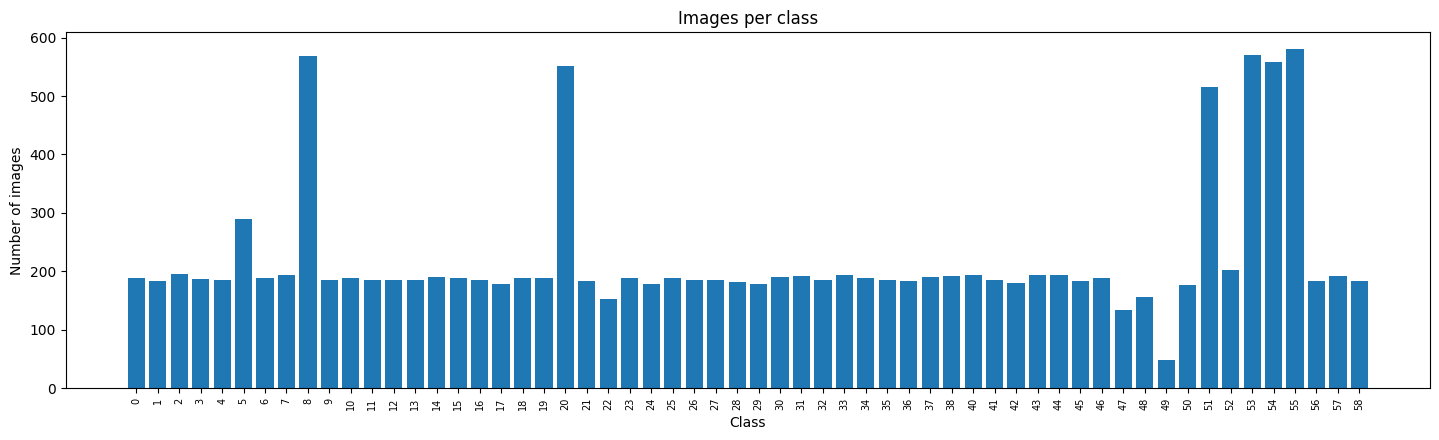

,class,images
0,0,189
1,1,183
2,2,195
3,3,187
4,4,186
5,5,290
6,6,189
7,7,194
8,8,569
9,9,185



Image width  min/median/max: 32 / 32 / 32
Image height min/median/max: 32 / 32 / 32


In [ ]:
# ---------- Dataset analysis ----------
counts = Counter(all_labels)
count_df = pd.DataFrame({'class': class_names,
                         'images': [counts.get(i, 0) for i in range(num_classes)]})

print('Number of classes :', num_classes)
print('Number of images  :', len(all_paths))
print(count_df['images'].describe().round(1).to_string())

imbalance_ratio = count_df['images'].max() / max(count_df['images'].min(), 1)
print(f'\nImbalance ratio (largest class / smallest class): {imbalance_ratio:.2f}')
USE_CLASS_WEIGHTS = imbalance_ratio > CFG['imbalance_threshold']
if USE_CLASS_WEIGHTS:
    print('-> Dataset is noticeably imbalanced: a class-weighted loss WILL be used, so rare '
          'classes are not ignored in favour of frequent ones.')
else:
    print('-> Dataset is reasonably balanced: plain cross-entropy will be used (no extra complexity).')

# Class distribution plot
plt.figure(figsize=(max(10, num_classes * 0.25), 4.5))
plt.bar(range(num_classes), count_df['images'])
plt.xticks(range(num_classes), class_names, rotation=90, fontsize=7)
plt.xlabel('Class'); plt.ylabel('Number of images'); plt.title('Images per class')
plt.tight_layout()
plt.savefig(PLOT_DIR / 'class_distribution.png', dpi=200)
plt.show()

count_df.to_csv(RESULT_DIR / 'images_per_class.csv', index=False)
display(count_df.T if num_classes <= 20 else count_df)

# Original image sizes (sample of up to 300 images)
rng = random.Random(SEED)
sizes = [Image.open(p).size for p in rng.sample(all_paths, min(300, len(all_paths)))]
w, h = zip(*sizes)
print(f'\nImage width  min/median/max: {min(w)} / {int(np.median(w))} / {max(w)}')
print(f'Image height min/median/max: {min(h)} / {int(np.median(h))} / {max(h)}')

## 7. Dataset Visualization
One example image from each class (first 20 classes shown).

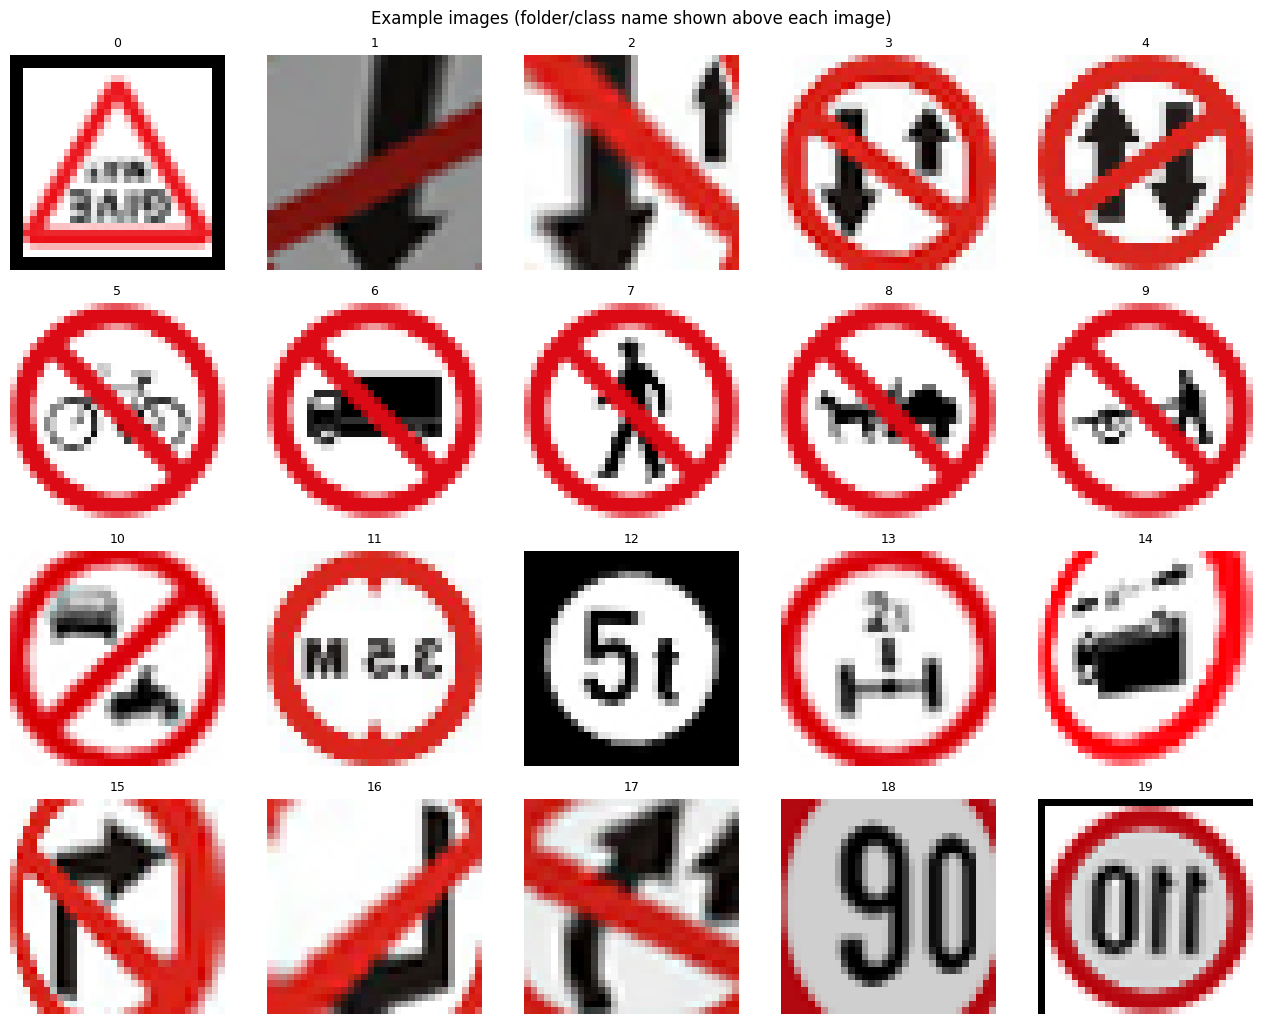

In [ ]:
def show_examples(max_classes=20, cols=5):
    shown = min(max_classes, num_classes)
    rows = int(np.ceil(shown / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.6, rows * 2.6))
    axes = np.array(axes).reshape(-1)
    for i in range(shown):
        idx = next(j for j, l in enumerate(all_labels) if l == i)
        axes[i].imshow(Image.open(all_paths[idx]).convert('RGB'))
        axes[i].set_title(f'{class_names[i]}', fontsize=9)
    for ax in axes:
        ax.axis('off')
    plt.suptitle('Example images (folder/class name shown above each image)')
    plt.tight_layout()
    plt.savefig(PLOT_DIR / 'dataset_examples.png', dpi=200)
    plt.show()

show_examples()

## 8. Data Preprocessing

| Step | Purpose |
|------|---------|
| **Image loading + RGB conversion** | Some images are grayscale/RGBA/palette; ResNet50 expects exactly 3 channels. |
| **Resize to 224 x 224** | ResNet50's standard input size, which is what the ImageNet pretrained weights were trained for. |
| **ToTensor** | Converts pixels 0-255 to floats 0-1 in (C, H, W) layout. |
| **Normalization (ImageNet mean/std)** | The pretrained backbone expects inputs with this statistics. It is also used for the from-scratch model so all three experiments see identical inputs. |

Validation and test images get **only** resize + normalization (no randomness), so evaluation is deterministic and comparable.

In [ ]:
IMG = CFG['img_size']
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet statistics

def get_eval_transform():
    # Used for validation AND test: deterministic, no augmentation.
    return transforms.Compose([
        transforms.Resize((IMG, IMG)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])

class TrafficSignDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths, self.labels, self.transform = paths, labels, transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')     # RGB conversion
        if self.transform:
            img = self.transform(img)
        return img, self.labels[i]

eval_tf = get_eval_transform()
print(eval_tf)

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 9. Data Augmentation (training set only)

| Augmentation | Why |
|--------------|-----|
| `RandomResizedCrop` (scale 0.75-1.0, ratio ~1) | Simulates signs at different distances / framing. Mild scale so the sign stays visible. |
| `RandomRotation(10)` | Signs are rarely perfectly upright (camera tilt, bent poles). |
| `RandomAffine` translation 5% | Signs are not always centred. |
| `ColorJitter` brightness/contrast 0.3 | Different lighting, time of day and camera quality. |

**No horizontal flip:** many signs are directional (e.g. *turn left* vs *turn right*), so flipping could change the label.

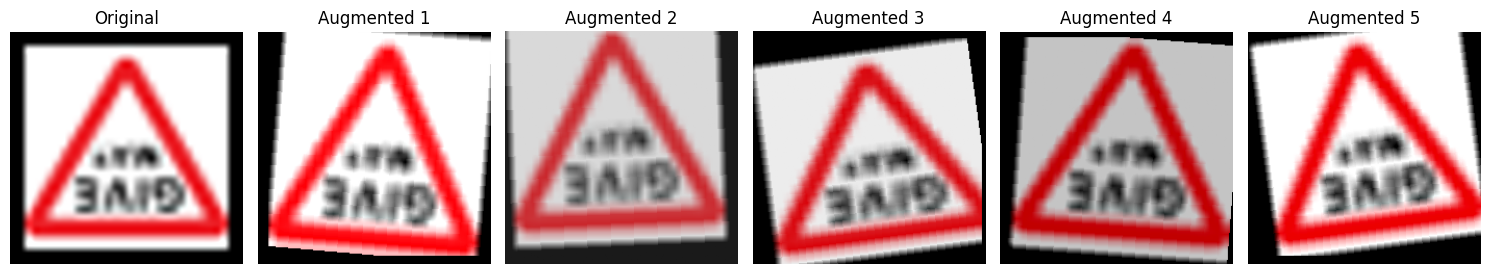

In [ ]:
def get_train_transform(normalize=True):
    t = [
        transforms.RandomResizedCrop(IMG, scale=(0.75, 1.0), ratio=(0.9, 1.1)),
        transforms.RandomRotation(10),
        transforms.RandomAffine(degrees=0, translate=(0.05, 0.05)),
        transforms.ColorJitter(brightness=0.3, contrast=0.3),
        transforms.ToTensor(),
    ]
    if normalize:
        t.append(transforms.Normalize(MEAN, STD))
    return transforms.Compose(t)

# Visual check: one original image and 5 random augmentations of it.
vis_tf = get_train_transform(normalize=False)
sample_img = Image.open(all_paths[0]).convert('RGB')
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(sample_img.resize((IMG, IMG))); axes[0].set_title('Original')
for k in range(1, 6):
    axes[k].imshow(vis_tf(sample_img).permute(1, 2, 0).numpy()); axes[k].set_title(f'Augmented {k}')
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.savefig(PLOT_DIR / 'augmentation_examples.png', dpi=200)
plt.show()

## 10. Train / Validation / Test Split
- **Stratified** split so every class appears in all three sets in the same proportion.
- Fixed random seed.
- If the dataset provides an **official test folder**, set `OFFICIAL_TEST_DIR` earlier and it will be preserved; otherwise a stratified 70/15/15 split is made.
- The **test set is not touched** until Section 17.

In [ ]:
if min(counts.values()) < 6:
    raise ValueError('Some classes have fewer than 6 images - too few to split into train/val/test. '
                     'Check the dataset (or merge/remove tiny classes).')

def stratified_split(paths, labels, test_size):
    return train_test_split(paths, labels, test_size=test_size,
                            stratify=labels, random_state=SEED)

if OFFICIAL_TEST_DIR is not None:
    tp, tl = list_samples(Path(OFFICIAL_TEST_DIR))
    test_paths, test_labels = clean_samples(tp, tl)
    test_set = set(test_paths)
    trval = [(p, l) for p, l in zip(all_paths, all_labels) if p not in test_set]
    trval_p, trval_l = [p for p, _ in trval], [l for _, l in trval]
    val_frac = CFG['val_ratio']
    print('Using the official test folder.')
else:
    trval_p, test_paths, trval_l, test_labels = stratified_split(all_paths, all_labels, CFG['test_ratio'])
    val_frac = CFG['val_ratio'] / (1 - CFG['test_ratio'])

train_paths, val_paths, train_labels, val_labels = stratified_split(trval_p, trval_l, val_frac)

# Safety check: no image may appear in more than one split
assert not (set(train_paths) & set(val_paths))
assert not (set(train_paths) & set(test_paths))
assert not (set(val_paths) & set(test_paths))

print(f'Train: {len(train_paths)} | Validation: {len(val_paths)} | Test: {len(test_paths)}')
split_df = pd.DataFrame({
    'class': class_names,
    'train': [Counter(train_labels).get(i, 0) for i in range(num_classes)],
    'val'  : [Counter(val_labels).get(i, 0) for i in range(num_classes)],
    'test' : [Counter(test_labels).get(i, 0) for i in range(num_classes)],
})
split_df.to_csv(RESULT_DIR / 'split_counts_per_class.csv', index=False)
display(split_df.head(10))

# Save the exact split so it can be reproduced / inspected later
pd.DataFrame({'path': train_paths + val_paths + test_paths,
              'label': train_labels + val_labels + test_labels,
              'split': ['train'] * len(train_paths) + ['val'] * len(val_paths) + ['test'] * len(test_paths)}
             ).to_csv(RESULT_DIR / 'split_assignment.csv', index=False)

Train: 9047 | Validation: 1939 | Test: 1939


,class,train,val,test
0,0,133,28,28
1,1,128,28,27
2,2,137,29,29
3,3,131,28,28
4,4,130,28,28
5,5,203,43,44
6,6,133,28,28
7,7,136,29,29
8,8,399,85,85
9,9,129,28,28


## 11. Data Loaders

In [ ]:
def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

g = torch.Generator(); g.manual_seed(SEED)

train_ds = TrafficSignDataset(train_paths, train_labels, get_train_transform())   # augmentation ON
val_ds   = TrafficSignDataset(val_paths,   val_labels,   get_eval_transform())    # no augmentation
test_ds  = TrafficSignDataset(test_paths,  test_labels,  get_eval_transform())    # no augmentation

loader_args = dict(batch_size=CFG['batch_size'], num_workers=CFG['num_workers'],
                   pin_memory=(device.type == 'cuda'), worker_init_fn=seed_worker)
train_loader = DataLoader(train_ds, shuffle=True, generator=g, **loader_args)
val_loader   = DataLoader(val_ds,   shuffle=False, **loader_args)
test_loader  = DataLoader(test_ds,  shuffle=False, **loader_args)

# Optional class weights (only if the dataset is imbalanced, see Section 6)
if USE_CLASS_WEIGHTS:
    tc = np.array([Counter(train_labels).get(i, 0) for i in range(num_classes)], dtype=np.float32)
    class_weights = torch.tensor(len(train_labels) / (num_classes * np.maximum(tc, 1)), dtype=torch.float32).to(device)
else:
    class_weights = None
criterion = nn.CrossEntropyLoss(weight=class_weights)

xb, yb = next(iter(train_loader))
print('One training batch:', tuple(xb.shape), tuple(yb.shape))
print('Loss function     :', criterion)

One training batch: (64, 3, 224, 224) (64,)
Loss function     : CrossEntropyLoss()


In [ ]:
# ---------- Experiment configuration summary (saved to Drive) ----------
def experiment_config():
    return {
        'python_version': platform.python_version(),
        'torch_version': torch.__version__,
        'torchvision_version': torchvision.__version__,
        'gpu': torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU only',
        'dataset': DATASET_SLUG,
        'dataset_size_after_cleaning': len(all_paths),
        'train_val_test_sizes': [len(train_paths), len(val_paths), len(test_paths)],
        'num_classes': num_classes,
        'image_size': CFG['img_size'],
        'batch_size': CFG['batch_size'],
        'learning_rates': {'scratch': CFG['lr_scratch'], 'frozen_head': CFG['lr_head'],
                           'fine_tune': CFG['lr_finetune']},
        'epochs_max': {'scratch': CFG['epochs_scratch'], 'frozen': CFG['epochs_frozen'],
                       'fine_tune': CFG['epochs_finetune']},
        'optimizer': f"AdamW (weight_decay={CFG['weight_decay']})",
        'scheduler': 'CosineAnnealingLR (T_max = max epochs of each run)',
        'early_stopping_patience': CFG['patience'],
        'class_weighted_loss': bool(USE_CLASS_WEIGHTS),
        'mixed_precision': USE_AMP,
        'fine_tune_unfrozen_layers': CFG['ft_unfreeze'],
        'random_seed': SEED,
    }

exp_cfg = experiment_config()
print(json.dumps(exp_cfg, indent=2))
with open(RESULT_DIR / 'experiment_config.json', 'w') as f:
    json.dump(exp_cfg, f, indent=2)

{
  "python_version": "3.13.15",
  "torch_version": "2.11.0+cu128",
  "torchvision_version": "0.26.0+cu128",
  "gpu": "Tesla T4",
  "dataset": "neelpratiksha/indian-traffic-sign-dataset",
  "dataset_size_after_cleaning": 12925,
  "train_val_test_sizes": [
    9047,
    1939,
    1939
  ],
  "num_classes": 58,
  "image_size": 224,
  "batch_size": 64,
  "learning_rates": {
    "scratch": 0.001,
    "frozen_head": 0.001,
    "fine_tune": 0.0001
  },
  "epochs_max": {
    "scratch": 40,
    "frozen": 15,
    "fine_tune": 20
  },
  "optimizer": "AdamW (weight_decay=0.0001)",
  "scheduler": "CosineAnnealingLR (T_max = max epochs of each run)",
  "early_stopping_patience": 7,
  "class_weighted_loss": true,
  "mixed_precision": true,
  "fine_tune_unfrozen_layers": [
    "layer4"
  ],
  "random_seed": 42
}


## 12. ResNet50 From Scratch

### 12.1 Reusable model and training utilities
The same functions are used for all three experiments (no duplicated code).

The **same classification head** (`Dropout -> Linear(2048, N)`) is used in all three models so the only differences are *initialisation* and *which layers are trainable*.

In [ ]:
# ---------------- Model construction ----------------
def build_resnet50(num_classes, pretrained):
    weights = models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.resnet50(weights=weights)
    in_features = model.fc.in_features                     # 2048
    model.fc = nn.Sequential(nn.Dropout(CFG['dropout']),   # replaces the 1000-class ImageNet layer
                             nn.Linear(in_features, num_classes))
    return model

def freeze_backbone(model):
    # Freeze everything except the new classification head (model.fc).
    for name, p in model.named_parameters():
        p.requires_grad = name.startswith('fc.')

def unfreeze_layers(model, layer_names):
    # Make the given ResNet stages (e.g. 'layer4') trainable again.
    for name, p in model.named_parameters():
        if any(name.startswith(l + '.') for l in layer_names):
            p.requires_grad = True

def summarize_trainable(model, title=''):
    print(f'--- {title} ---')
    total_tr = total_fr = 0
    for name, child in model.named_children():
        n_tr = sum(p.numel() for p in child.parameters() if p.requires_grad)
        n_fr = sum(p.numel() for p in child.parameters() if not p.requires_grad)
        if n_tr + n_fr == 0:
            continue
        status = 'TRAINABLE' if n_fr == 0 else ('FROZEN   ' if n_tr == 0 else 'MIXED    ')
        print(f'  {name:<8} {status}  trainable={n_tr:>10,}  frozen={n_fr:>10,}')
        total_tr += n_tr; total_fr += n_fr
    print(f'  TOTAL: trainable={total_tr:,} | frozen={total_fr:,} | all={total_tr + total_fr:,}')

def keep_frozen_bn_eval(model):
    # BatchNorm layers whose weights are frozen must also keep their running statistics fixed,
    # otherwise the "frozen" backbone would still change during training.
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and all(not p.requires_grad for p in m.parameters()):
            m.eval()

In [ ]:
# ---------------- Training / evaluation loop ----------------
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    # One pass over a loader. Trains if an optimizer is given, otherwise only evaluates.
    training = optimizer is not None
    model.train() if training else model.eval()
    if training:
        keep_frozen_bn_eval(model)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x = x.to(device, non_blocking=True); y = y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=USE_AMP):
                out = model(x)
                loss = criterion(out, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def train_model(model, run_name, optimizer, scheduler, criterion, epochs, patience, resume=False):
    # Trains a model, saves checkpoints + best model to Drive, applies early stopping.
    ckpt_last = CKPT_DIR / f'{run_name}_last.pt'
    ckpt_best = CKPT_DIR / f'{run_name}_best.pt'
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'lr': [], 'time': []}
    start_epoch, best_acc, best_loss, bad_epochs = 0, -1.0, float('inf'), 0

    if resume and ckpt_last.exists():
        ck = torch.load(ckpt_last, map_location=device, weights_only=False)
        model.load_state_dict(ck['model_state'])
        optimizer.load_state_dict(ck['optimizer_state'])
        if scheduler is not None and ck.get('scheduler_state') is not None:
            scheduler.load_state_dict(ck['scheduler_state'])
        start_epoch = ck['epoch'] + 1
        history, best_acc = ck['history'], ck['best_val_acc']
        best_loss, bad_epochs = ck['best_val_loss'], ck['epochs_no_improve']
        print(f'Resumed {run_name} from epoch {start_epoch} (best val acc so far {best_acc:.4f})')

    for epoch in range(start_epoch, epochs):
        if bad_epochs >= patience:
            break
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scaler)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        lr_now = optimizer.param_groups[0]['lr']
        if scheduler is not None:
            scheduler.step()

        for k, v in zip(['train_loss', 'val_loss', 'train_acc', 'val_acc', 'lr', 'time'],
                        [tr_loss, va_loss, tr_acc, va_acc, lr_now, time.time() - t0]):
            history[k].append(v)

        # "Best" = higher validation accuracy (ties broken by lower validation loss)
        improved = (va_acc > best_acc) or (va_acc == best_acc and va_loss < best_loss)
        if improved:
            best_acc, best_loss, bad_epochs = va_acc, va_loss, 0
        else:
            bad_epochs += 1

        ck = {'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(),
              'scheduler_state': scheduler.state_dict() if scheduler is not None else None,
              'epoch': epoch, 'val_acc': va_acc, 'val_loss': va_loss,
              'best_val_acc': best_acc, 'best_val_loss': best_loss,
              'epochs_no_improve': bad_epochs, 'history': history}
        torch.save(ck, ckpt_last)                     # for resuming
        if improved:
            torch.save(ck, ckpt_best)                 # best model by validation performance

        print(f'[{run_name}] epoch {epoch + 1:>2}/{epochs} | '
              f'train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f} | '
              f'lr {lr_now:.2e} | {time.time() - t0:.0f}s' + ('  <- best' if improved else ''))

    if bad_epochs >= patience:
        print(f'Early stopping: no validation improvement for {patience} epochs.')

    # Restore the best weights and store the history
    best_ck = torch.load(ckpt_best, map_location=device, weights_only=False)
    model.load_state_dict(best_ck['model_state'])
    print(f'Loaded best model of {run_name}: epoch {best_ck["epoch"] + 1}, val acc {best_ck["val_acc"]:.4f}')
    with open(RESULT_DIR / f'{run_name}_history.json', 'w') as f:
        json.dump(history, f, indent=2)
    return model, history

In [ ]:
# ---------------- Model 1: ResNet50 with random initialisation ----------------
set_seed()
model_scratch = build_resnet50(num_classes, pretrained=False).to(device)
summarize_trainable(model_scratch, 'ResNet50 from scratch (all layers trainable)')

--- ResNet50 from scratch (all layers trainable) ---
  conv1    TRAINABLE  trainable=     9,408  frozen=         0
  bn1      TRAINABLE  trainable=       128  frozen=         0
  layer1   TRAINABLE  trainable=   215,808  frozen=         0
  layer2   TRAINABLE  trainable= 1,219,584  frozen=         0
  layer3   TRAINABLE  trainable= 7,098,368  frozen=         0
  layer4   TRAINABLE  trainable=14,964,736  frozen=         0
  fc       TRAINABLE  trainable=   118,842  frozen=         0
  TOTAL: trainable=23,626,874 | frozen=0 | all=23,626,874


## 13. Training From Scratch
All layers start from random weights and are all trained. A larger learning rate (1e-3) is acceptable because nothing pretrained can be damaged.

In [ ]:
set_seed()
opt_scratch = torch.optim.AdamW(model_scratch.parameters(), lr=CFG['lr_scratch'],
                                weight_decay=CFG['weight_decay'])
sched_scratch = torch.optim.lr_scheduler.CosineAnnealingLR(opt_scratch, T_max=CFG['epochs_scratch'])

model_scratch, hist_scratch = train_model(
    model_scratch, 'resnet50_scratch', opt_scratch, sched_scratch, criterion,
    epochs=CFG['epochs_scratch'], patience=CFG['patience'], resume=RESUME)

[resnet50_scratch] epoch  1/40 | train loss 0.3418 acc 0.8854 | val loss 0.4043 acc 0.8721 | lr 1.00e-03 | 48s  <- best
[resnet50_scratch] epoch  2/40 | train loss 0.3078 acc 0.8952 | val loss 0.3019 acc 0.8948 | lr 9.98e-04 | 61s  <- best
[resnet50_scratch] epoch  3/40 | train loss 0.3433 acc 0.8857 | val loss 0.3443 acc 0.8798 | lr 9.94e-04 | 58s
[resnet50_scratch] epoch  4/40 | train loss 0.2743 acc 0.8989 | val loss 0.3493 acc 0.8886 | lr 9.86e-04 | 60s
[resnet50_scratch] epoch  5/40 | train loss 0.2404 acc 0.9067 | val loss 0.3246 acc 0.8865 | lr 9.76e-04 | 53s
[resnet50_scratch] epoch  6/40 | train loss 0.2552 acc 0.9067 | val loss 0.2556 acc 0.9067 | lr 9.62e-04 | 60s  <- best
[resnet50_scratch] epoch  7/40 | train loss 0.2343 acc 0.9142 | val loss 0.3240 acc 0.9067 | lr 9.46e-04 | 58s
[resnet50_scratch] epoch  8/40 | train loss 0.2364 acc 0.9125 | val loss 0.2698 acc 0.9010 | lr 9.26e-04 | 53s
[resnet50_scratch] epoch  9/40 | train loss 0.2237 acc 0.9126 | val loss 0.3128 acc 0

## 14. Pretrained ResNet50
ResNet50 is loaded with **ImageNet (IMAGENET1K_V1)** weights. The original 1000-class layer is replaced by a new `Dropout -> Linear(2048, N)` head, where N is the number of Indian traffic-sign classes found in the dataset.

In [ ]:
set_seed()
model_frozen = build_resnet50(num_classes, pretrained=True).to(device)
print('Pretrained ResNet50 loaded. New head:', model_frozen.fc)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 171MB/s]


Pretrained ResNet50 loaded. New head: Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=2048, out_features=58, bias=True)
)


## 15. Feature Extraction (Stage 1)

```
ImageNet-pretrained ResNet50 backbone  ->  FROZEN
              |
     New classification head           ->  TRAINABLE
              |
      N traffic-sign classes
```
The backbone acts as a fixed feature extractor; only the new head learns to map those features to Indian traffic-sign classes.

In [ ]:
freeze_backbone(model_frozen)
summarize_trainable(model_frozen, 'Stage 1: frozen backbone + trainable head')

--- Stage 1: frozen backbone + trainable head ---
  conv1    FROZEN     trainable=         0  frozen=     9,408
  bn1      FROZEN     trainable=         0  frozen=       128
  layer1   FROZEN     trainable=         0  frozen=   215,808
  layer2   FROZEN     trainable=         0  frozen= 1,219,584
  layer3   FROZEN     trainable=         0  frozen= 7,098,368
  layer4   FROZEN     trainable=         0  frozen=14,964,736
  fc       TRAINABLE  trainable=   118,842  frozen=         0
  TOTAL: trainable=118,842 | frozen=23,508,032 | all=23,626,874


In [ ]:
set_seed()
opt_frozen = torch.optim.AdamW(filter(lambda p: p.requires_grad, model_frozen.parameters()),
                               lr=CFG['lr_head'], weight_decay=CFG['weight_decay'])
sched_frozen = torch.optim.lr_scheduler.CosineAnnealingLR(opt_frozen, T_max=CFG['epochs_frozen'])

model_frozen, hist_frozen = train_model(
    model_frozen, 'resnet50_frozen', opt_frozen, sched_frozen, criterion,
    epochs=CFG['epochs_frozen'], patience=CFG['patience'], resume=RESUME)

[resnet50_frozen] epoch  1/15 | train loss 2.5212 acc 0.4468 | val loss 1.7968 acc 0.6013 | lr 1.00e-03 | 40s  <- best
[resnet50_frozen] epoch  2/15 | train loss 1.4551 acc 0.6692 | val loss 1.3743 acc 0.6756 | lr 9.89e-04 | 39s  <- best
[resnet50_frozen] epoch  3/15 | train loss 1.1562 acc 0.7265 | val loss 1.1871 acc 0.6947 | lr 9.57e-04 | 41s  <- best
[resnet50_frozen] epoch  4/15 | train loss 1.0232 acc 0.7482 | val loss 1.0505 acc 0.7380 | lr 9.05e-04 | 41s  <- best
[resnet50_frozen] epoch  5/15 | train loss 0.9319 acc 0.7693 | val loss 1.0168 acc 0.7272 | lr 8.35e-04 | 42s
[resnet50_frozen] epoch  6/15 | train loss 0.8589 acc 0.7835 | val loss 0.9554 acc 0.7416 | lr 7.50e-04 | 40s  <- best
[resnet50_frozen] epoch  7/15 | train loss 0.8009 acc 0.7988 | val loss 0.8994 acc 0.7643 | lr 6.55e-04 | 41s  <- best
[resnet50_frozen] epoch  8/15 | train loss 0.7648 acc 0.8059 | val loss 0.8590 acc 0.7808 | lr 5.52e-04 | 41s  <- best
[resnet50_frozen] epoch  9/15 | train loss 0.7367 acc 0.8

## 16. Fine-Tuning (Stage 2)

Starting from the **best feature-extraction model**, only the deeper stage(s) listed in `CFG['ft_unfreeze']` (default `layer4`) are unfrozen:

```
conv1, bn1, layer1, layer2, layer3  ->  FROZEN
layer4 (deepest residual stage)     ->  TRAINABLE
classification head                 ->  TRAINABLE
```

**Why only later layers?**
- Early layers learn generic features (edges, corners, colours, textures) that transfer well to traffic signs, so there is little to gain from changing them.
- Deeper layers learn more task-specific patterns and benefit most from adapting to the new domain.
- Training fewer parameters lowers the risk of over-fitting on a small dataset and needs less time and memory.
- A **smaller learning rate (1e-4)** avoids overwriting useful pretrained weights.

The whole network is intentionally *not* unfrozen.

In [ ]:
set_seed()
model_ft = build_resnet50(num_classes, pretrained=False).to(device)
ck = torch.load(CKPT_DIR / 'resnet50_frozen_best.pt', map_location=device, weights_only=False)
model_ft.load_state_dict(ck['model_state'])          # start from the best Stage-1 weights
print(f'Loaded best Stage-1 model (epoch {ck["epoch"] + 1}, val acc {ck["val_acc"]:.4f})')

freeze_backbone(model_ft)
unfreeze_layers(model_ft, CFG['ft_unfreeze'])
summarize_trainable(model_ft, f"Stage 2: unfrozen = {CFG['ft_unfreeze']} + head")

Loaded best Stage-1 model (epoch 15, val acc 0.7953)
--- Stage 2: unfrozen = ['layer4'] + head ---
  conv1    FROZEN     trainable=         0  frozen=     9,408
  bn1      FROZEN     trainable=         0  frozen=       128
  layer1   FROZEN     trainable=         0  frozen=   215,808
  layer2   FROZEN     trainable=         0  frozen= 1,219,584
  layer3   FROZEN     trainable=         0  frozen= 7,098,368
  layer4   TRAINABLE  trainable=14,964,736  frozen=         0
  fc       TRAINABLE  trainable=   118,842  frozen=         0
  TOTAL: trainable=15,083,578 | frozen=8,543,296 | all=23,626,874


In [ ]:
set_seed()
opt_ft = torch.optim.AdamW(filter(lambda p: p.requires_grad, model_ft.parameters()),
                           lr=CFG['lr_finetune'], weight_decay=CFG['weight_decay'])
sched_ft = torch.optim.lr_scheduler.CosineAnnealingLR(opt_ft, T_max=CFG['epochs_finetune'])

model_ft, hist_ft = train_model(
    model_ft, 'resnet50_finetune', opt_ft, sched_ft, criterion,
    epochs=CFG['epochs_finetune'], patience=CFG['patience'], resume=RESUME)

[resnet50_finetune] epoch  1/20 | train loss 0.4761 acc 0.8476 | val loss 0.3262 acc 0.8850 | lr 1.00e-04 | 48s  <- best
[resnet50_finetune] epoch  2/20 | train loss 0.2802 acc 0.8964 | val loss 0.2803 acc 0.8969 | lr 9.94e-05 | 44s  <- best
[resnet50_finetune] epoch  3/20 | train loss 0.2204 acc 0.9156 | val loss 0.2664 acc 0.8963 | lr 9.76e-05 | 50s
[resnet50_finetune] epoch  4/20 | train loss 0.2007 acc 0.9219 | val loss 0.2632 acc 0.9077 | lr 9.46e-05 | 46s  <- best
[resnet50_finetune] epoch  5/20 | train loss 0.1833 acc 0.9285 | val loss 0.2318 acc 0.9108 | lr 9.05e-05 | 49s  <- best
[resnet50_finetune] epoch  6/20 | train loss 0.1754 acc 0.9328 | val loss 0.2595 acc 0.9020 | lr 8.54e-05 | 49s
[resnet50_finetune] epoch  7/20 | train loss 0.1640 acc 0.9357 | val loss 0.2419 acc 0.9108 | lr 7.94e-05 | 49s
[resnet50_finetune] epoch  8/20 | train loss 0.1493 acc 0.9402 | val loss 0.2244 acc 0.9139 | lr 7.27e-05 | 51s  <- best
[resnet50_finetune] epoch  9/20 | train loss 0.1430 acc 0.9

## 17. Test Evaluation
The **best checkpoint** (chosen using validation accuracy only) of each of the three models is evaluated on the **same held-out test set**.

- **Accuracy** - fraction of correct predictions.
- **Precision / Recall / F1 (macro)** - computed per class, then averaged with equal weight per class, so rare classes count as much as frequent ones.
- **Weighted F1** - per-class F1 averaged by class size (reported for completeness).
- **Top-5 accuracy** - true class is among the 5 highest-scoring predictions.

In [ ]:
def load_best_model(run_name):
    m = build_resnet50(num_classes, pretrained=False).to(device)
    ck = torch.load(CKPT_DIR / f'{run_name}_best.pt', map_location=device, weights_only=False)
    m.load_state_dict(ck['model_state'])
    return m.eval(), ck['epoch'] + 1

@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, preds, probs = [], [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            out = model(x)
        p = torch.softmax(out.float(), dim=1)
        probs.append(p.cpu().numpy()); preds.append(p.argmax(1).cpu().numpy()); ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(preds), np.concatenate(probs)

def compute_metrics(y_true, y_pred, probs):
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    _, _, f1_w, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
    k = min(5, num_classes)
    topk = np.argsort(-probs, axis=1)[:, :k]
    return {'Accuracy': accuracy_score(y_true, y_pred), 'Precision': prec, 'Recall': rec,
            'Macro F1': f1, 'Weighted F1': f1_w,
            'Top-5 Accuracy': float((topk == y_true[:, None]).any(axis=1).mean())}

RUNS = [('resnet50_scratch',  'From Scratch'),
        ('resnet50_frozen',   'Pretrained + Frozen'),
        ('resnet50_finetune', 'Pretrained + Fine-tuned')]

predictions, rows = {}, []
for run_name, method in RUNS:
    model_eval, best_ep = load_best_model(run_name)
    y_true, y_pred, probs = predict(model_eval, test_loader)      # test set used here for the first time
    predictions[run_name] = (y_true, y_pred)
    m = compute_metrics(y_true, y_pred, probs)
    rows.append({'Model': 'ResNet50', 'Training Method': method, **m, 'Best epoch': best_ep})

    report = classification_report(y_true, y_pred, labels=list(range(num_classes)),
                                   target_names=class_names, zero_division=0)
    with open(RESULT_DIR / f'{run_name}_classification_report.txt', 'w') as f:
        f.write(report)
    del model_eval

results_df = pd.DataFrame(rows)
results_df.to_csv(RESULT_DIR / 'final_results.csv', index=False)
print('Test set size:', len(test_paths))
print('Precision and Recall are macro-averaged.')
display(results_df.style.format({c: '{:.4f}' for c in
        ['Accuracy', 'Precision', 'Recall', 'Macro F1', 'Weighted F1', 'Top-5 Accuracy']}))

Test set size: 1939
Precision and Recall are macro-averaged.


,Model,Training Method,Accuracy,Precision,Recall,Macro F1,Weighted F1,Top-5 Accuracy,Best epoch
0,ResNet50,From Scratch,0.9314,0.9046,0.9071,0.9035,0.9299,0.9959,31
1,ResNet50,Pretrained + Frozen,0.7953,0.7736,0.7647,0.7520,0.7917,0.9603,15
2,ResNet50,Pretrained + Fine-tuned,0.9232,0.8931,0.8938,0.8924,0.9224,0.9954,14


In [ ]:
# Full per-class classification report of the fine-tuned model
print(open(RESULT_DIR / 'resnet50_finetune_classification_report.txt').read())

              precision    recall  f1-score   support

           0       0.97      1.00      0.98        28
           1       1.00      0.96      0.98        27
           2       0.76      0.90      0.83        29
           3       0.83      0.71      0.77        28
           4       0.97      1.00      0.98        28
           5       0.98      1.00      0.99        44
           6       1.00      1.00      1.00        28
           7       1.00      0.97      0.98        29
           8       1.00      0.98      0.99        85
           9       1.00      0.96      0.98        28
          10       1.00      1.00      1.00        28
          11       1.00      1.00      1.00        28
          12       0.96      0.96      0.96        28
          13       1.00      1.00      1.00        28
          14       1.00      0.97      0.98        29
          15       1.00      1.00      1.00        28
          16       1.00      0.96      0.98        28
          17       0.96    

## 18. Confusion Matrix
Rows = true class, columns = predicted class (row-normalised so every class is comparable). The fine-tuned model is shown; matrices for the other two models are saved to the plots folder.

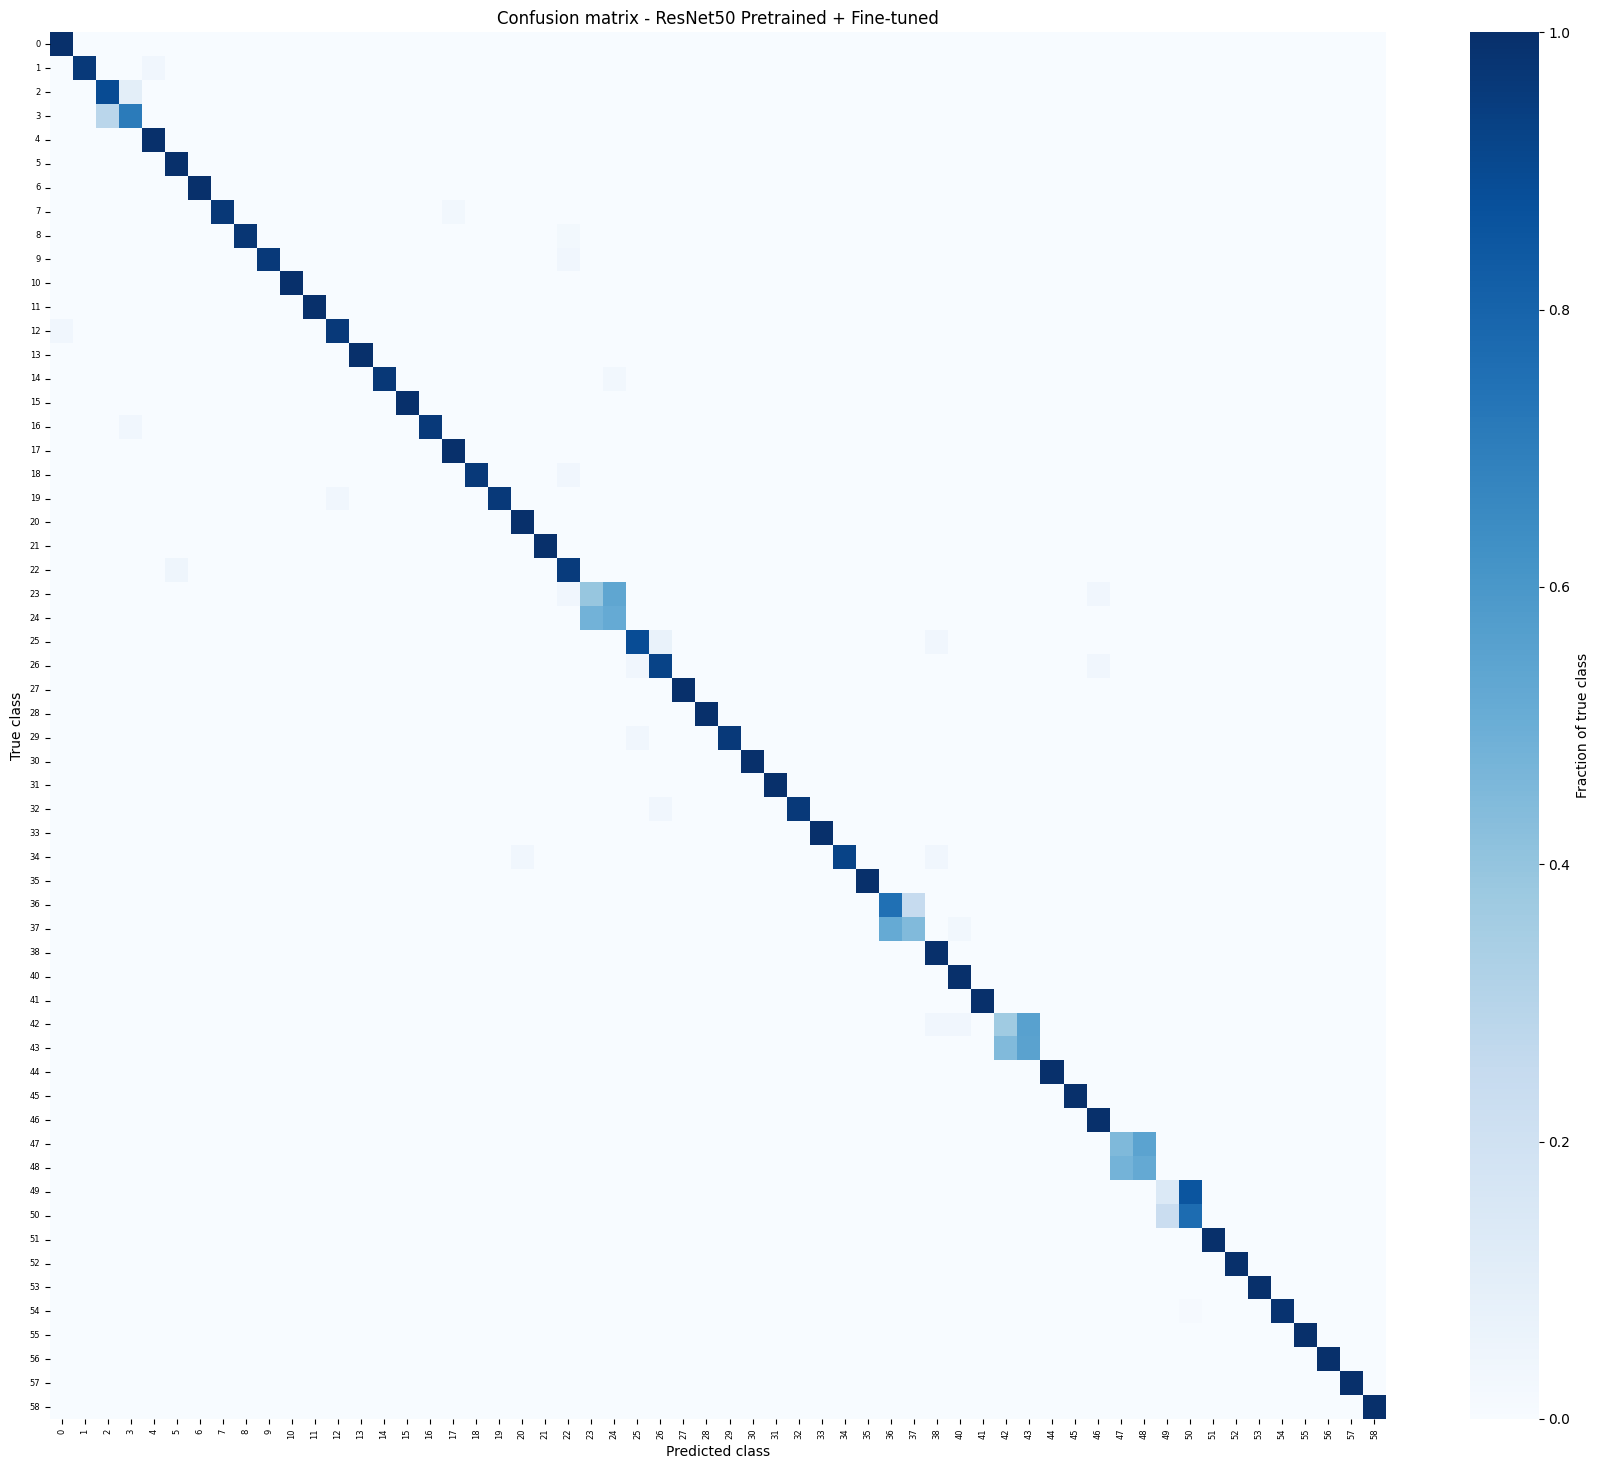

Most frequent confusions (fine-tuned model):
  true     37 -> predicted     36 : 15 images
  true     42 -> predicted     43 : 15 images
  true     23 -> predicted     24 : 15 images
  true     43 -> predicted     42 : 13 images
  true     24 -> predicted     23 : 13 images
  true     48 -> predicted     47 : 11 images
  true     47 -> predicted     48 : 11 images
  true      3 -> predicted      2 : 8 images
  true     36 -> predicted     37 : 7 images
  true     50 -> predicted     49 : 6 images


In [ ]:
def plot_confusion(run_name, title, show=True):
    y_true, y_pred = predictions[run_name]
    cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    size = min(max(8, num_classes * 0.3), 22)
    plt.figure(figsize=(size, size * 0.85))
    sns.heatmap(cm_norm, cmap='Blues', vmin=0, vmax=1, xticklabels=class_names, yticklabels=class_names,
                annot=(num_classes <= 15), fmt='.2f', cbar_kws={'label': 'Fraction of true class'})
    plt.xlabel('Predicted class'); plt.ylabel('True class'); plt.title(title)
    plt.xticks(fontsize=6, rotation=90); plt.yticks(fontsize=6, rotation=0)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f'confusion_matrix_{run_name}.png', dpi=200)
    plt.show() if show else plt.close()
    pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(RESULT_DIR / f'confusion_matrix_{run_name}.csv')
    return cm

cms = {}
for run_name, method in RUNS:
    cms[run_name] = plot_confusion(run_name, f'Confusion matrix - ResNet50 {method}',
                                   show=(run_name == 'resnet50_finetune'))

# Most frequent mistakes of the fine-tuned model
cm = cms['resnet50_finetune'].copy()
np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:10], cm.shape))[0]
print('Most frequent confusions (fine-tuned model):')
for t, p in top:
    if cm[t, p] > 0:
        print(f'  true {class_names[t]:>6} -> predicted {class_names[p]:>6} : {cm[t, p]} images')

## 19. Model Comparison

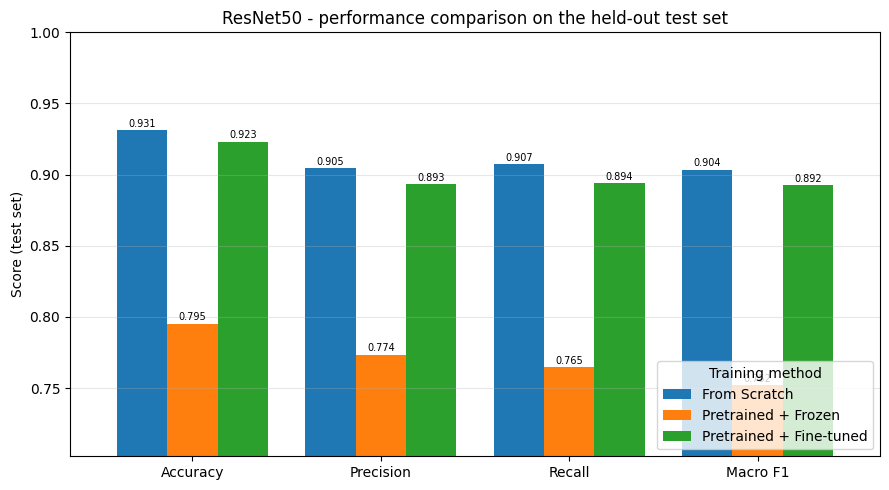

Note: the y-axis starts at 0.7 - read bar heights from the printed values.


In [ ]:
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'Macro F1']
plot_df = results_df.set_index('Training Method')[metrics_to_plot]

ax = plot_df.T.plot(kind='bar', figsize=(9, 5), width=0.8)
ax.set_ylabel('Score (test set)')
ax.set_title('ResNet50 - performance comparison on the held-out test set')
lo = max(0.0, float(plot_df.values.min()) - 0.05)
ax.set_ylim(lo, 1.0)
ax.set_xticklabels(metrics_to_plot, rotation=0)
ax.legend(title='Training method', loc='lower right')
ax.grid(axis='y', alpha=0.3)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.3f', fontsize=7, padding=1)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'model_comparison.png', dpi=200)
plt.show()
print('Note: the y-axis starts at', round(lo, 2), '- read bar heights from the printed values.')

## 20. Result Visualization - Training Curves
Training vs validation accuracy and loss for each experiment. (Training accuracy/loss are measured on *augmented* images in training mode, so they can look lower than validation values early on; this is normal.)

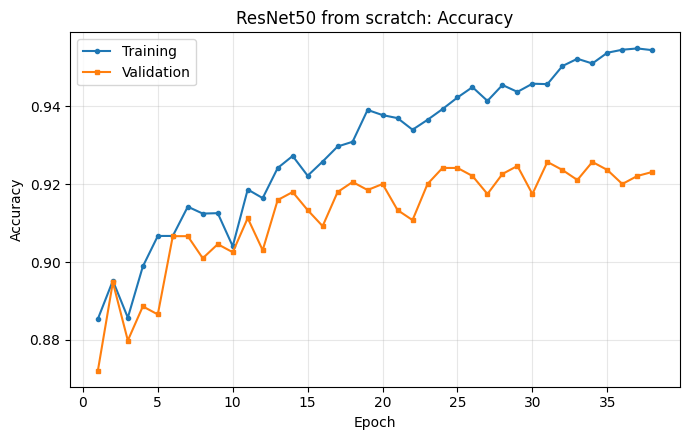

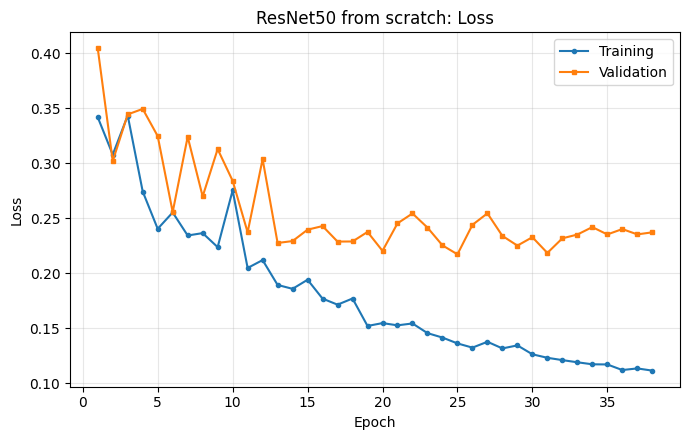

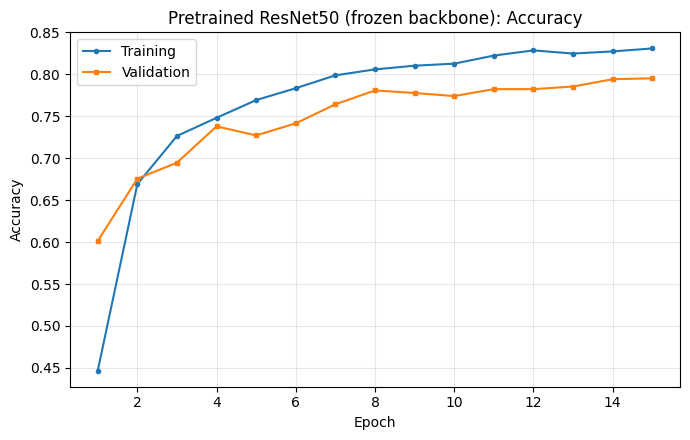

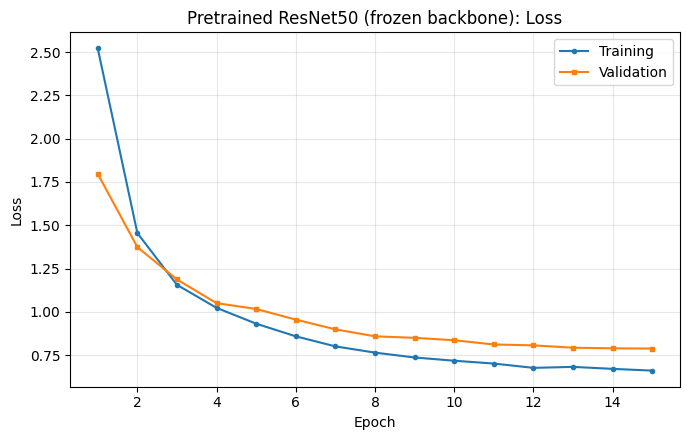

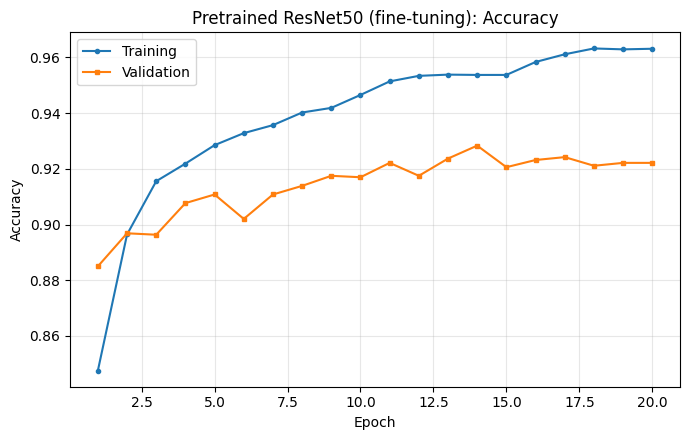

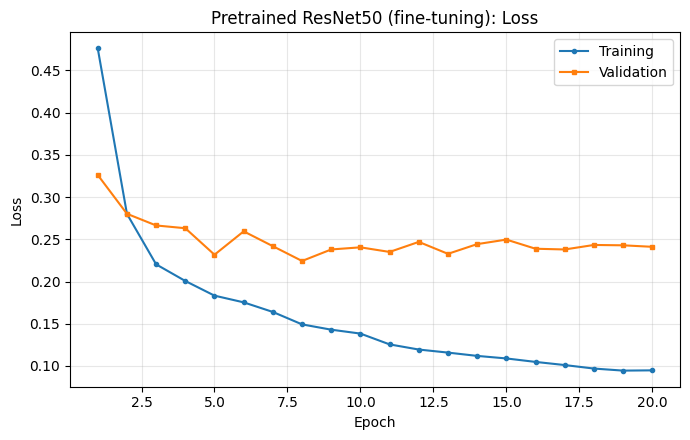

Saved plots: ['augmentation_examples.png', 'class_distribution.png', 'confusion_matrix_resnet50_finetune.png', 'confusion_matrix_resnet50_frozen.png', 'confusion_matrix_resnet50_scratch.png', 'dataset_examples.png', 'finetune_acc.png', 'finetune_loss.png', 'model_comparison.png', 'pretrained_frozen_acc.png', 'pretrained_frozen_loss.png', 'scratch_acc.png', 'scratch_loss.png']


In [ ]:
def plot_history(hist, title, file_prefix):
    epochs = range(1, len(hist['train_acc']) + 1)
    for metric, label in [('acc', 'Accuracy'), ('loss', 'Loss')]:
        plt.figure(figsize=(7, 4.5))
        plt.plot(epochs, hist[f'train_{metric}'], marker='o', markersize=3, label='Training')
        plt.plot(epochs, hist[f'val_{metric}'], marker='s', markersize=3, label='Validation')
        plt.xlabel('Epoch'); plt.ylabel(label); plt.title(f'{title}: {label}')
        plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
        plt.savefig(PLOT_DIR / f'{file_prefix}_{metric}.png', dpi=200)
        plt.show()

plot_history(hist_scratch, 'ResNet50 from scratch', 'scratch')
plot_history(hist_frozen,  'Pretrained ResNet50 (frozen backbone)', 'pretrained_frozen')
plot_history(hist_ft,      'Pretrained ResNet50 (fine-tuning)', 'finetune')
print('Saved plots:', sorted(p.name for p in PLOT_DIR.glob('*.png')))

## 21. Save Final Models
Final weights (`state_dict`), class names, the configuration and the results table are saved to Google Drive.

Saved /content/drive/MyDrive/Traffic_Sign_ResNet50/models/resnet50_scratch_final.pt
Saved /content/drive/MyDrive/Traffic_Sign_ResNet50/models/resnet50_frozen_final.pt
Saved /content/drive/MyDrive/Traffic_Sign_ResNet50/models/resnet50_finetune_final.pt


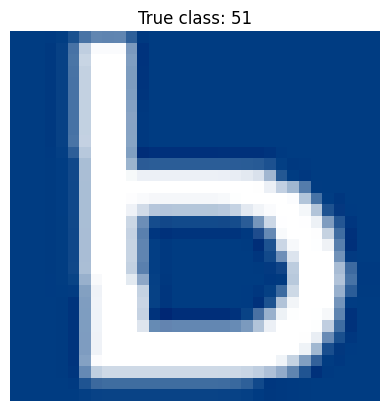

  predicted class     51  probability 1.000
  predicted class     24  probability 0.000
  predicted class     23  probability 0.000


In [ ]:
for run_name, method in RUNS:
    m, best_ep = load_best_model(run_name)
    torch.save({'model_state': m.state_dict(), 'class_names': class_names,
                'num_classes': num_classes, 'img_size': IMG, 'mean': MEAN, 'std': STD,
                'method': method, 'best_epoch': best_ep},
               MODEL_DIR / f'{run_name}_final.pt')
    print('Saved', MODEL_DIR / f'{run_name}_final.pt')

with open(MODEL_DIR / 'class_names.json', 'w') as f:
    json.dump(class_names, f, indent=2)
results_df.to_csv(RESULT_DIR / 'final_results.csv', index=False)

# ---------- Inference on a single image (the final classification system) ----------
def predict_image(image_path, model, top_k=3):
    model.eval()
    img = Image.open(image_path).convert('RGB')
    x = eval_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(x).float(), dim=1)[0]
    vals, idx = probs.topk(min(top_k, num_classes))
    return [(class_names[i], float(v)) for v, i in zip(vals, idx)]

final_model, _ = load_best_model('resnet50_finetune')
demo_path = random.Random(SEED).choice(test_paths)
plt.imshow(Image.open(demo_path).convert('RGB')); plt.axis('off')
plt.title('True class: ' + class_names[test_labels[test_paths.index(demo_path)]]); plt.show()
for cls, p in predict_image(demo_path, final_model):
    print(f'  predicted class {cls:>6}  probability {p:.3f}')

## 22. Final Analysis
The next cell only **reads back the actual results** and reports them factually. Interpret them in your report after looking at the curves and confusion matrix - do not write conclusions before seeing the numbers.

In [ ]:
print('==== FINAL RESULTS (test set) ====')
display(results_df.style.format({c: '{:.4f}' for c in
        ['Accuracy', 'Precision', 'Recall', 'Macro F1', 'Weighted F1', 'Top-5 Accuracy']}))

by = results_df.set_index('Training Method')
best_method = by['Macro F1'].idxmax()
print(f"Highest macro F1 : {best_method} ({by.loc[best_method, 'Macro F1']:.4f})")
print(f"Highest accuracy : {by['Accuracy'].idxmax()} ({by['Accuracy'].max():.4f})")

print('\nDifference in test accuracy (percentage points):')
sc, fr, ft = (by.loc[m, 'Accuracy'] * 100 for m in ['From Scratch', 'Pretrained + Frozen', 'Pretrained + Fine-tuned'])
print(f'  Frozen      - Scratch : {fr - sc:+.2f}')
print(f'  Fine-tuned  - Scratch : {ft - sc:+.2f}')
print(f'  Fine-tuned  - Frozen  : {ft - fr:+.2f}')

print('\nTraining behaviour (from the histories):')
for name, h in [('From scratch', hist_scratch), ('Frozen', hist_frozen), ('Fine-tuning', hist_ft)]:
    print(f"  {name:<12} epochs run: {len(h['val_acc']):>2} | best val acc: {max(h['val_acc']):.4f} | "
          f"final train-val acc gap: {h['train_acc'][-1] - h['val_acc'][-1]:+.4f} | "
          f"total time: {sum(h['time']) / 60:.1f} min")

==== FINAL RESULTS (test set) ====


,Model,Training Method,Accuracy,Precision,Recall,Macro F1,Weighted F1,Top-5 Accuracy,Best epoch
0,ResNet50,From Scratch,0.9314,0.9046,0.9071,0.9035,0.9299,0.9959,31
1,ResNet50,Pretrained + Frozen,0.7953,0.7736,0.7647,0.7520,0.7917,0.9603,15
2,ResNet50,Pretrained + Fine-tuned,0.9232,0.8931,0.8938,0.8924,0.9224,0.9954,14


Highest macro F1 : From Scratch (0.9035)
Highest accuracy : From Scratch (0.9314)

Difference in test accuracy (percentage points):
  Frozen      - Scratch : -13.62
  Fine-tuned  - Scratch : -0.83
  Fine-tuned  - Frozen  : +12.79

Training behaviour (from the histories):
  From scratch epochs run: 38 | best val acc: 0.9257 | final train-val acc gap: +0.0313 | total time: 35.4 min
  Frozen       epochs run: 15 | best val acc: 0.7953 | final train-val acc gap: +0.0356 | total time: 10.0 min
  Fine-tuning  epochs run: 20 | best val acc: 0.9283 | final train-val acc gap: +0.0410 | total time: 15.3 min


### Points to discuss in the report (answer using YOUR printed results)

1. **Scratch vs pretrained:** How do the three models differ in test accuracy and macro F1? Did the pretrained models converge in fewer epochs (see the curves)?
2. **Frozen vs fine-tuned:** Did unfreezing `layer4` change the results compared with the frozen backbone? By how much?
3. **Generalisation:** Compare the train/validation gap in each curve. Is there evidence of over-fitting?
4. **Errors:** Which classes are confused most often (Section 18)? Are they visually similar signs?
5. **Training cost:** Compare the training time and the number of trainable parameters of the three approaches.

### Limitations to state honestly
- **Single run per model with one seed** - differences of a few tenths of a percent may be within run-to-run noise. Repeating with several seeds would be needed for statistical claims.
- **Fine-tuning received extra training:** it continues from the frozen model, so it has seen more total epochs than the frozen model alone. State this when comparing.
- **Dataset artefacts:** exact duplicate files were removed, but *near*-duplicates (e.g. pre-augmented copies of the same photo in the dataset) cannot be detected automatically and could make test scores optimistic. Inspect the dataset's description on Kaggle.
- The dataset may not represent all real-world conditions (night, rain, motion blur, occlusion).
- No hyper-parameter search was performed; the same fixed settings were used for all approaches.

TOP CONFUSION PAIRS - FINE-TUNED RESNET50
Total incorrect predictions: 149

 1. True: 37                        → Predicted: 36                        Count: 15
 2. True: 42                        → Predicted: 43                        Count: 15
 3. True: 23                        → Predicted: 24                        Count: 15
 4. True: 24                        → Predicted: 23                        Count: 13
 5. True: 43                        → Predicted: 42                        Count: 13
 6. True: 47                        → Predicted: 48                        Count: 11
 7. True: 48                        → Predicted: 47                        Count: 11
 8. True: 3                         → Predicted: 2                         Count: 8
 9. True: 36                        → Predicted: 37                        Count: 7
10. True: 50                        → Predicted: 49                        Count: 6
11. True: 49                        → Predicted: 50                        Co

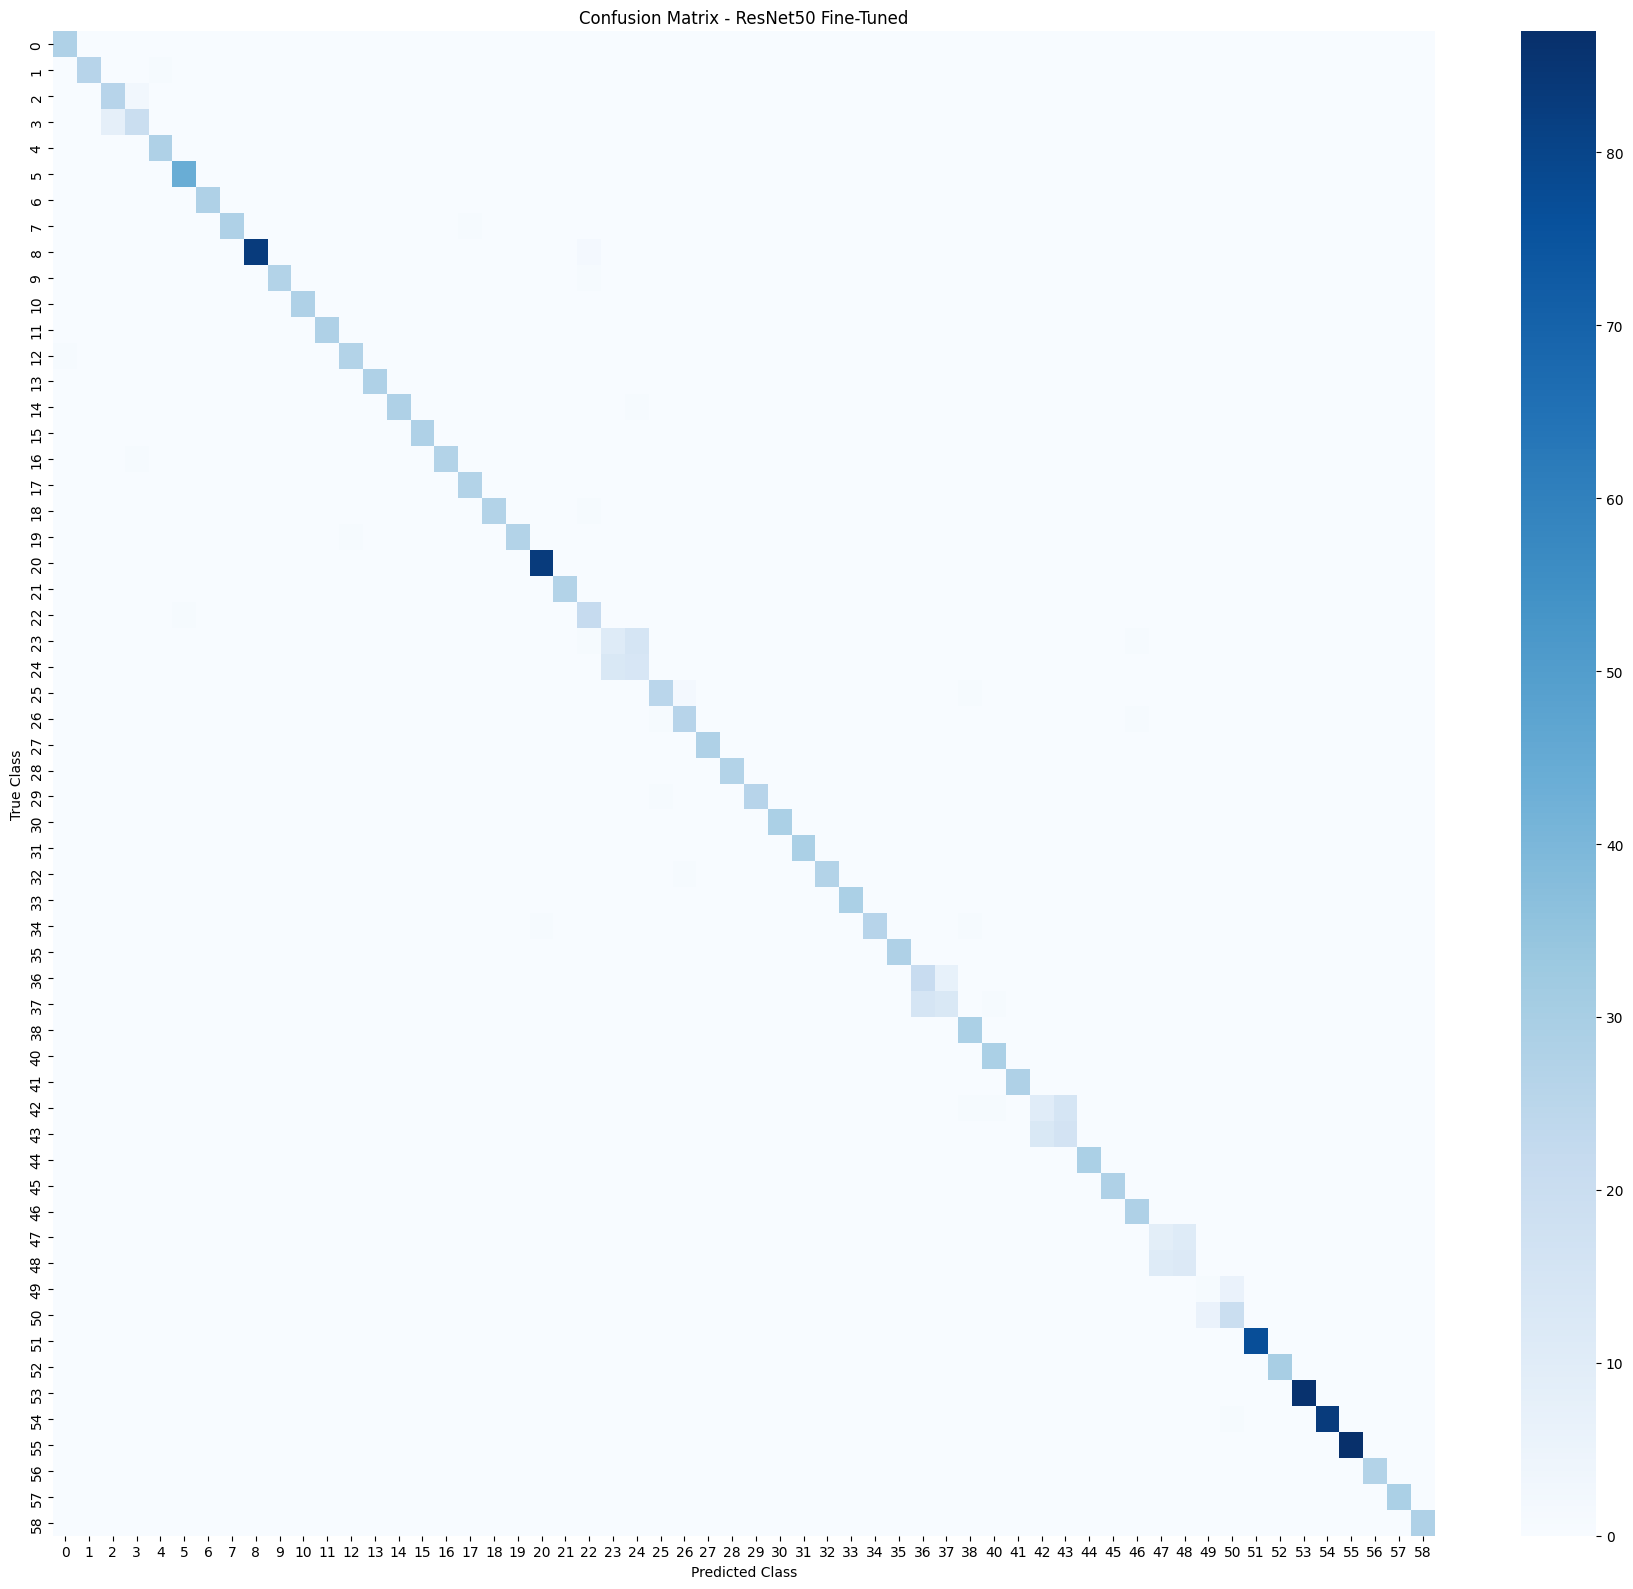


MOST COMMON CONFUSION FOR EACH CLASS


,True Class,Most Confused With,Confusion Count
0,1,4,1
1,2,3,3
2,3,2,8
3,7,17,1
4,8,22,2
5,9,22,1
6,12,0,1
7,14,24,1
8,16,3,1
9,18,22,1


Saved: /content/drive/MyDrive/Traffic_Sign_ResNet50/results/resnet50_finetune_per_class_confusions.csv


In [ ]:
# ============================================================
# Top Confusion Pairs - Fine-Tuned ResNet50
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Use the already trained fine-tuned model
final_model, best_ep = load_best_model('resnet50_finetune')

# Get predictions on the held-out test set
y_true, y_pred, probs = predict(final_model, test_loader)

# Build confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))

# ------------------------------------------------------------
# 1. Extract only INCORRECT predictions
# ------------------------------------------------------------
confusions = []

for true_idx in range(num_classes):
    for pred_idx in range(num_classes):
        if true_idx != pred_idx and cm[true_idx, pred_idx] > 0:
            confusions.append({
                'True Class': class_names[true_idx],
                'Predicted Class': class_names[pred_idx],
                'Count': int(cm[true_idx, pred_idx])
            })

# Sort from most frequent confusion to least frequent
confusions_df = pd.DataFrame(confusions).sort_values(
    'Count', ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# 2. Print top confusion pairs
# ------------------------------------------------------------
print("============================================================")
print("TOP CONFUSION PAIRS - FINE-TUNED RESNET50")
print("============================================================")

print(f"Total incorrect predictions: {(np.array(y_true) != np.array(y_pred)).sum()}")
print()

top_n = 20

for i, row in confusions_df.head(top_n).iterrows():
    print(
        f"{i+1:2d}. True: {row['True Class']:<25} "
        f"→ Predicted: {row['Predicted Class']:<25} "
        f"Count: {row['Count']}"
    )

# Save the complete confusion-pair table
confusions_df.to_csv(
    RESULT_DIR / 'resnet50_finetune_confusion_pairs.csv',
    index=False
)

print()
print("Saved:",
      RESULT_DIR / 'resnet50_finetune_confusion_pairs.csv')


# ------------------------------------------------------------
# 3. Show confusion matrix
# ------------------------------------------------------------
plt.figure(figsize=(18, 16))

sns.heatmap(
    cm,
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    annot=False
)

plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.title('Confusion Matrix - ResNet50 Fine-Tuned')
plt.tight_layout()

plt.savefig(
    PLOT_DIR / 'confusion_matrix_resnet50_finetune_final.png',
    dpi=200
)

plt.show()


# ------------------------------------------------------------
# 4. Find the most confused class for each true class
# ------------------------------------------------------------
print("\n============================================================")
print("MOST COMMON CONFUSION FOR EACH CLASS")
print("============================================================")

per_class_confusions = []

for true_idx in range(num_classes):

    row = cm[true_idx].copy()
    row[true_idx] = 0  # ignore correct predictions

    if row.sum() == 0:
        continue

    pred_idx = np.argmax(row)

    per_class_confusions.append({
        'True Class': class_names[true_idx],
        'Most Confused With': class_names[pred_idx],
        'Confusion Count': int(row[pred_idx])
    })

per_class_df = pd.DataFrame(per_class_confusions)

display(per_class_df)

per_class_df.to_csv(
    RESULT_DIR / 'resnet50_finetune_per_class_confusions.csv',
    index=False
)

print("Saved:",
      RESULT_DIR / 'resnet50_finetune_per_class_confusions.csv')

The fine-tuned ResNet50 produced 149 incorrect predictions on the 1,939-image test set, with most predictions concentrated on the diagonal of the confusion matrix. The errors were not uniformly distributed across the 58 classes; instead, several class pairs accounted for a substantial proportion of the mistakes. The most frequent confusions were between classes 37 and 36, 42 and 43, 23 and 24, and 47 and 48. These classes also showed relatively low per-class F1-scores, indicating that the confusion matrix and classification report provide consistent evidence of specific difficult categories. Class 49 was the weakest class, with an F1-score of 0.14 and only seven test samples, and was frequently confused with class 50. In contrast, many other classes achieved F1-scores close to 1.00. These results indicate that the model learned the majority of traffic-sign categories effectively, while the remaining errors were concentrated in a limited number of difficult or poorly represented classes.